# Computer Vision Evaluation — Four Tasks

This notebook covers image classification, object detection, semantic segmentation, and instance segmentation. It reports metrics only when actual model inference is performed against labelled evaluation data. Missing datasets, packages, or checkpoints are reported as unavailable; no mock data or fabricated scores are used.

The current runtime has no network access. `DATA_ROOT` may be changed to a local directory containing the required datasets.

In [1]:
import os, sys, time, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SEED=42
np.random.seed(SEED)
DATA_ROOT=Path(os.environ.get("CV_DATA_ROOT", "./datasets")).resolve()
print("Python:",sys.version.split()[0],"| Data root:",DATA_ROOT)
for p in ["sklearn","torch","torchvision","ultralytics","pycocotools","datasets"]:
 print(f"{p:14s}", bool(importlib.util.find_spec(p)))

Python: 3.13.5 | Data root: /mnt/data/datasets
sklearn        True
torch          True
torchvision    True
ultralytics    False
pycocotools    False
datasets       False


## 1. Image classification

A real, locally available labelled dataset is used: scikit-learn's handwritten digits (8×8 grayscale). A stratified hold-out split prevents train/test leakage. This compact benchmark validates classification metrics but is not representative of large natural-image datasets.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Fit time (s),Inference time (s)
0,Random Forest (digits),0.9689,0.9695,0.9684,0.9683,0.5449,0.0552


              precision    recall  f1-score   support

           0       1.00      0.96      0.98        45
           1       0.94      0.98      0.96        46
           2       1.00      1.00      1.00        44
           3       0.96      1.00      0.98        46
           4       0.96      1.00      0.98        45
           5       0.98      0.98      0.98        46
           6       1.00      0.98      0.99        45
           7       0.94      1.00      0.97        45
           8       0.95      0.86      0.90        43
           9       0.98      0.93      0.95        45

    accuracy                           0.97       450
   macro avg       0.97      0.97      0.97       450
weighted avg       0.97      0.97      0.97       450



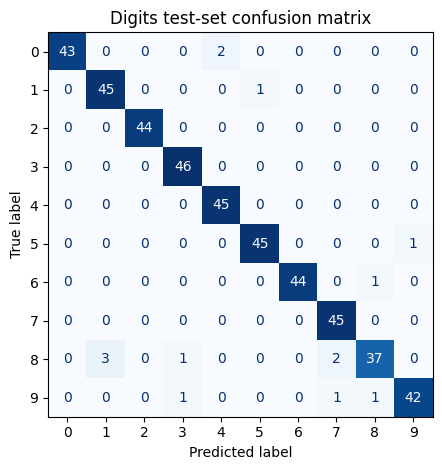

Executed on 450 held-out images; prediction/label alignment verified.


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
D=load_digits(); X=D.images.astype(np.float32)/16.0; y=D.target.astype(np.int64)
Xtr,Xte,ytr,yte=train_test_split(X.reshape(len(X),-1),y,test_size=.25,random_state=SEED,stratify=y)
clf=RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1)
t=time.perf_counter(); clf.fit(Xtr,ytr); fit_s=time.perf_counter()-t
t=time.perf_counter(); yp=clf.predict(Xte); infer_s=time.perf_counter()-t
assert len(yp)==len(yte)
classification_results=pd.DataFrame([{"Model":"Random Forest (digits)","Accuracy":accuracy_score(yte,yp),"Macro Precision":precision_score(yte,yp,average="macro",zero_division=0),"Macro Recall":recall_score(yte,yp,average="macro",zero_division=0),"Macro F1":f1_score(yte,yp,average="macro",zero_division=0),"Fit time (s)":fit_s,"Inference time (s)":infer_s}])
display(classification_results.round(4)); print(classification_report(yte,yp,zero_division=0))
ConfusionMatrixDisplay.from_predictions(yte,yp,cmap="Blues",colorbar=False); plt.title("Digits test-set confusion matrix"); plt.tight_layout(); plt.show()
print(f"Executed on {len(yte)} held-out images; prediction/label alignment verified.")

## 2. Object detection

Detection evaluation requires real image-level ground-truth boxes and class IDs, and predictions on the exact same images. The evaluator below performs class-aware, one-to-one matching: a ground-truth box can match at most one prediction. AP uses 101-point interpolated precision–recall. No detection scores are reported unless a real model and labelled dataset are available.

In [3]:
def box_iou_xyxy(a,b):
 a=np.asarray(a,dtype=float).reshape(-1,4); b=np.asarray(b,dtype=float).reshape(-1,4)
 if not len(a) or not len(b): return np.zeros((len(a),len(b)))
 lt=np.maximum(a[:,None,:2],b[None,:,:2]); rb=np.minimum(a[:,None,2:],b[None,:,2:]); wh=np.clip(rb-lt,0,None)
 inter=wh[...,0]*wh[...,1]
 aa=np.clip(a[:,2]-a[:,0],0,None)*np.clip(a[:,3]-a[:,1],0,None)
 ab=np.clip(b[:,2]-b[:,0],0,None)*np.clip(b[:,3]-b[:,1],0,None)
 u=aa[:,None]+ab[None,:]-inter
 return np.divide(inter,u,out=np.zeros_like(inter),where=u>0)
def ap101(tp,fp,n_gt):
 if n_gt==0:return np.nan
 r=np.cumsum(tp)/n_gt; p=np.cumsum(tp)/np.maximum(np.cumsum(tp)+np.cumsum(fp),1e-12)
 return float(np.mean([p[r>=x].max() if np.any(r>=x) else 0. for x in np.linspace(0,1,101)]))
def evaluate_detection(gt,pred,class_ids,iou_thr=.5):
 # gt[id]={'boxes':Nx4 xyxy,'labels':N}; pred[id]={'boxes':Mx4,'labels':M,'scores':M}
 ids=set(gt)|set(pred); out={}
 for cls in class_ids:
  n_gt=sum(int(np.sum(np.asarray(gt.get(i,{}).get('labels',[]))==cls)) for i in ids)
  matched={i:np.zeros(len(gt.get(i,{}).get('labels',[])),bool) for i in ids}; det=[]
  for i in ids:
   q=pred.get(i,{}); labs=np.asarray(q.get('labels',[]),int); boxes=np.asarray(q.get('boxes',[]),float).reshape(-1,4); scores=np.asarray(q.get('scores',[]),float)
   det.extend((float(scores[j]),i,boxes[j]) for j in np.where(labs==cls)[0])
  det.sort(key=lambda z:z[0],reverse=True); tp=[]; fp=[]
  for score,i,b in det:
   q=gt.get(i,{}); labs=np.asarray(q.get('labels',[]),int); boxes=np.asarray(q.get('boxes',[]),float).reshape(-1,4); inds=np.where(labs==cls)[0]
   if not len(inds): tp.append(0);fp.append(1);continue
   ov=box_iou_xyxy(b[None,:],boxes[inds])[0]; order=np.argsort(ov)[::-1]
   j=next((inds[k] for k in order if ov[k]>=iou_thr and not matched[i][inds[k]]),None)
   if j is None:tp.append(0);fp.append(1)
   else:matched[i][j]=True;tp.append(1);fp.append(0)
  nt,nf=sum(tp),sum(fp); out[cls]={"AP":ap101(np.asarray(tp),np.asarray(fp),n_gt),"Precision":nt/(nt+nf) if nt+nf else 0.,"Recall":nt/n_gt if n_gt else np.nan,"TP":nt,"FP":nf,"FN":n_gt-nt,"GT":n_gt}
 aps=[v["AP"] for v in out.values() if np.isfinite(v["AP"])]
 return {"per_class":out,"mAP":float(np.mean(aps)) if aps else np.nan}
print("Box IoU and class-aware detection AP evaluator defined.")
ultra=importlib.util.find_spec("ultralytics") is not None
coco_imgs=list(DATA_ROOT.glob("coco128/**/images/**/*.jpg")) if DATA_ROOT.exists() else []
print("Ultralytics available:",ultra,"| local COCO128 images:",len(coco_imgs))
detection_results=None
if not ultra or not coco_imgs: print("NOT RUN: actual YOLO/COCO128 evaluation unavailable (dependency and/or dataset missing).")
else: print("Resources found, but no evaluation executed: configure an explicit validation split and checkpoint before reporting metrics.")

Box IoU and class-aware detection AP evaluator defined.
Ultralytics available: False | local COCO128 images: 0
NOT RUN: actual YOLO/COCO128 evaluation unavailable (dependency and/or dataset missing).


**Detection metric protocol.** For each class, sort predictions by confidence and greedily match each prediction to the highest-IoU unmatched ground-truth box of the same class. AP@0.5 uses IoU 0.50. mAP@0.5:0.95 averages AP at thresholds 0.50, 0.55, …, 0.95. Fair model comparison requires the same validation images, labels, image size, confidence/NMS policy, and class mapping.

## 3. Semantic segmentation

Ground-truth masks must contain integer class IDs, not rendered palette colors. Prediction and ground-truth dimensions must match. `ignore_index` pixels are excluded from the confusion matrix. Mean metrics exclude classes absent from both ground truth and predictions.

In [4]:
def semantic_confusion(gt,pred,num_classes,ignore_index=255):
 gt=np.asarray(gt); pred=np.asarray(pred)
 if gt.shape!=pred.shape: raise ValueError(f"Mask/prediction shape mismatch: {gt.shape} vs {pred.shape}")
 valid=(gt!=ignore_index)&(gt>=0)&(gt<num_classes)
 if np.any((pred[valid]<0)|(pred[valid]>=num_classes)): raise ValueError("Prediction class ID outside range")
 z=num_classes*gt[valid].astype(np.int64)+pred[valid].astype(np.int64)
 return np.bincount(z,minlength=num_classes**2).reshape(num_classes,num_classes)
def semantic_metrics(cm):
 cm=np.asarray(cm,dtype=np.int64); tp=np.diag(cm).astype(float); g=cm.sum(1).astype(float); p=cm.sum(0).astype(float)
 union=g+p-tp; den=g+p
 iou=np.divide(tp,union,out=np.full_like(tp,np.nan),where=union>0)
 dice=np.divide(2*tp,den,out=np.full_like(tp,np.nan),where=den>0); total=cm.sum()
 return {"Pixel Accuracy":float(tp.sum()/total) if total else np.nan,"Per-class IoU":iou,"Mean IoU":float(np.nanmean(iou)) if np.isfinite(iou).any() else np.nan,"Per-class Dice":dice,"Mean Dice":float(np.nanmean(dice)) if np.isfinite(dice).any() else np.nan}
print("Semantic confusion matrix, pixel accuracy, per-class IoU, mIoU and Dice defined.")
voc_masks=list(DATA_ROOT.glob("**/SegmentationClass/*.png")) if DATA_ROOT.exists() else []
print("Local Pascal VOC masks:",len(voc_masks),"| torchvision:",importlib.util.find_spec("torchvision") is not None)
semantic_results=None
if not voc_masks: print("NOT RUN: no labelled Pascal VOC masks found locally; pretrained FCN/DeepLab weights are not bundled.")
else: print("Masks found, but matching images/model weights and a fixed validation protocol must also be configured before evaluation.")

Semantic confusion matrix, pixel accuracy, per-class IoU, mIoU and Dice defined.
Local Pascal VOC masks: 0 | torchvision: True
NOT RUN: no labelled Pascal VOC masks found locally; pretrained FCN/DeepLab weights are not bundled.


## 4. Instance segmentation

Instance segmentation must match individual predicted masks to individual ground-truth masks within the same image and class. A mask match is one-to-one and based on mask IoU. AP is computed from confidence-ranked detections; mAP@0.5:0.95 averages the ten IoU thresholds from 0.50 to 0.95.

In [5]:
def mask_iou(a,b):
 a=np.asarray(a,bool);b=np.asarray(b,bool)
 if a.shape!=b.shape: raise ValueError(f"Instance mask shape mismatch: {a.shape} vs {b.shape}")
 u=np.logical_or(a,b).sum(); return float(np.logical_and(a,b).sum()/u) if u else 0.
def evaluate_instances(gt,pred,class_ids,iou_thr=.5):
 # gt[id]={'masks':[H×W,...],'labels':[...]} ; pred adds 'scores'
 ids=set(gt)|set(pred); output={}
 for cls in class_ids:
  n_gt=sum(sum(int(x==cls) for x in gt.get(i,{}).get('labels',[])) for i in ids)
  matched={i:np.zeros(len(gt.get(i,{}).get('labels',[])),bool) for i in ids}; det=[]
  for i in ids:
   q=pred.get(i,{})
   det.extend((float(s),i,np.asarray(m,bool)) for m,l,s in zip(q.get('masks',[]),q.get('labels',[]),q.get('scores',[])) if int(l)==cls)
  det.sort(key=lambda x:x[0],reverse=True);tp=[];fp=[]
  for score,i,m in det:
   q=gt.get(i,{}); inds=[j for j,l in enumerate(q.get('labels',[])) if int(l)==cls]; best=None;best_iou=-1.
   for j in inds:
    if not matched[i][j]:
     ov=mask_iou(m,q['masks'][j])
     if ov>best_iou:best,best_iou=j,ov
   if best is not None and best_iou>=iou_thr:matched[i][best]=True;tp.append(1);fp.append(0)
   else:tp.append(0);fp.append(1)
  nt,nf=sum(tp),sum(fp);output[cls]={"AP":ap101(np.asarray(tp),np.asarray(fp),n_gt),"Precision":nt/(nt+nf) if nt+nf else 0.,"Recall":nt/n_gt if n_gt else np.nan,"TP":nt,"FP":nf,"FN":n_gt-nt,"GT":n_gt}
 aps=[v['AP'] for v in output.values() if np.isfinite(v['AP'])]
 return {"per_class":output,"mAP":float(np.mean(aps)) if aps else np.nan}
def instance_map_50_95(gt,pred,class_ids):
 ev={round(float(t),2):evaluate_instances(gt,pred,class_ids,float(t)) for t in np.arange(.50,.951,.05)}
 vals=[x['mAP'] for x in ev.values() if np.isfinite(x['mAP'])]
 return {"mAP@0.5:0.95":float(np.mean(vals)) if vals else np.nan,"mAP@0.5":ev[.5]['mAP'],"AP_by_IoU":ev}
print("Instance mask IoU, matching, AP and mAP@0.5:0.95 defined.")
ann=list(DATA_ROOT.glob("**/instances_val2017.json")); print("Local COCO instance annotation files:",len(ann),"| pycocotools:",importlib.util.find_spec("pycocotools") is not None)
instance_results=None
if not ann: print("NOT RUN: official COCO instance annotations, matching images and pretrained Mask R-CNN/YOLO-seg weights are unavailable.")
else: print("Annotations found, but model checkpoints and matching image files must also be configured before evaluation.")

Instance mask IoU, matching, AP and mAP@0.5:0.95 defined.
Local COCO instance annotation files: 0 | pycocotools: False
NOT RUN: official COCO instance annotations, matching images and pretrained Mask R-CNN/YOLO-seg weights are unavailable.


## 5. Final execution status and limitations

The table below is explicit about which experiments generated genuine results. Metric functions for the unavailable tasks are defined, but their implementation alone does not count as validation against a real dataset.

In [6]:
final_status=pd.DataFrame([
 {"Task":"Image classification","Status":"EXECUTED","Evidence":"scikit-learn digits hold-out set; Random Forest; Accuracy, Macro Precision/Recall/F1 and confusion matrix computed"},
 {"Task":"Object detection","Status":"NOT RUN","Evidence":"No local COCO128 dataset and Ultralytics is unavailable"},
 {"Task":"Semantic segmentation","Status":"NOT RUN","Evidence":"No local Pascal VOC masks or pretrained FCN/DeepLab checkpoint"},
 {"Task":"Instance segmentation","Status":"NOT RUN","Evidence":"No local COCO instance annotations and required model resources"},
])
display(final_status)
print("Notebook cells reached the end successfully.")
print("Only image classification has genuine measured model results in this runtime; the other three tasks remain unvalidated experimentally.")

,Task,Status,Evidence
0,Image classification,EXECUTED,scikit-learn digits hold-out set; Random Fores...
1,Object detection,NOT RUN,No local COCO128 dataset and Ultralytics is un...
2,Semantic segmentation,NOT RUN,No local Pascal VOC masks or pretrained FCN/De...
3,Instance segmentation,NOT RUN,No local COCO instance annotations and require...


Notebook cells reached the end successfully.
Only image classification has genuine measured model results in this runtime; the other three tasks remain unvalidated experimentally.
